---

<table style="width:100%">
  <tr>
    <th>
        <div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> Конспект лекцій з предмету: </p>
<p style="text-align: center;"><b><h2>"Схемотехніка радіотехнічних пристроїв. Частина 2"</h2></b></p>
<p style="text-align: center;"><b><h3>Тема 8. Інтегратори, диференціатори, вимірювальні підсилювачі, перетворювачі U→I та I→U</h3></b></p>
<p style="text-align: center;"> Національний університет "Чернігівська політехніка"</p>
<hr/>
<p style="text-align: center;"><b>Питання теми:</b></p>
<ul style="text-align: left;">
  <li>2.10. Інтегратори на операційних підсилювачах: приклади реалізації, призначення та розрахункові співвідношення</li>
  <li>2.11. Диференціатори на операційних підсилювачах: приклади реалізації, призначення та розрахункові співвідношення</li>
  <li>2.12. Вимірювальні підсилювачі: приклади реалізації, призначення та області застосування</li>
  <li>2.13. Перетворювачі напруги в струм (джерела струму) на операційних підсилювачах</li>
  <li>2.14. Перетворювачі струму в напругу на операційних підсилювачах</li>
</ul>
</div>
    </th>
    <th>
<div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> <b>Викладач:</b> </p>
<p style="text-align: center;"> Доктор філософії</p>
<p style="text-align: center;"> Пахалюк Богдан Петрович</p>
<hr/>
<p style="text-align: center; font-size: 0.9em;">Тема 8 з 14</p>
</div>
    </th>
  </tr>
</table>

---


---

<p style="text-align: center;"><b>Зміст</b></p>

* [Інтегратори на ОП](#integrator)
    * [🔬 Інтерактивно: інтегратор на μA741: форми сигналів і дрейф (PySpice)](#integrator-interactive)
* [Диференціатори на ОП](#differentiator)
    * [🔬 Інтерактивно: диференціатор: ідеальний і скоригований (PySpice)](#diff-interactive)
* [Вимірювальні підсилювачі](#inamp)
    * [🔬 Інтерактивно: вимірювальний підсилювач проти простого диференціального: сигнал ЕКГ на тлі мережевої завади (PySpice)](#inamp-interactive)
* [Перетворювачі напруги в струм (джерела струму) на ОП](#v2i)
    * [🔬 Інтерактивно: незалежність струму від опору навантаження (PySpice)](#v2i-interactive)
* [Перетворювачі струму в напругу на ОП](#i2v)
    * [🔬 Інтерактивно: підсилювач фотодіода: стійкість і корекція (PySpice)](#tia-interactive)
* [📌 Підсумок теми](#topic-summary)
* [📚 Рекомендована література та ресурси](#references)

> 💡 Код демонстрацій та інтерактивних графіків **згорнуто**, щоб не відволікати від матеріалу. Щоб переглянути його, натисніть на «⋯» (або на смужку ліворуч від комірки). Для роботи інтерактивних елементів виконайте всі комірки: *Run → Run All Cells*.

---

**Підключення бібліотек.** NumPy/SciPy/Matplotlib — чисельні розрахунки та графіки, SymPy — символьні обчислення, ipywidgets — інтерактивні повзунки, PySpice + ngspice — моделювання схем (ОП μA741, таймер 555 та транзистори описано SPICE-моделями з теки `spice/`), schemdraw — побудова схем з умовними позначеннями за ДСТУ. Цю комірку потрібно виконати першою; у Google Colab вона спершу встановлює ngspice і бібліотеки (близько хвилини).

In [1]:
import sys, os
if 'google.colab' in sys.modules and not os.path.exists('/usr/lib/x86_64-linux-gnu/libngspice.so'):   # Google Colab: ngspice та бібліотеки (~1 хв)
    !apt-get -qq install -y ngspice libngspice0-dev > /dev/null
    %pip install -q PySpice==1.5 schemdraw==0.23 engineering_notation==0.13.3

# SPICE-моделі компонентів (ОП μA741, таймер 555, діоди, транзистори) лежать у теці spice/;
# якщо зошит відкрито окремо (напр. у Colab), завантажуємо їх із репозиторію
SPICE_DIR = 'spice'
if not os.path.isdir(SPICE_DIR):
    import urllib.request
    os.makedirs(SPICE_DIR, exist_ok=True)
    _repo = 'https://raw.githubusercontent.com/vim4all/Lectures_Schematics_of_radio_technical-devices_in_Ukrainian/main/spice/'
    for _f in ['uA741.lib', 'BIP-555.lib', '1N4007.mod', '2n2222a.lib', '2n3904.lib']:
        urllib.request.urlretrieve(_repo + _f, os.path.join(SPICE_DIR, _f))
def spice_model(name):
    return os.path.abspath(os.path.join(SPICE_DIR, name))

import warnings
warnings.filterwarnings('ignore', message='Unable to import Axes3D')
import sympy as smp
from sympy import symbols, Matrix, simplify, factor, solve, Eq, latex
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
from ipywidgets import interact, interactive, fixed, HBox, VBox, Output
import ipywidgets as widgets
from IPython.display import display, HTML, Markdown
%matplotlib inline
try:                                     # схеми й графіки — лише PNG (менший розмір зошитів)
    get_ipython().display_formatter.formatters['image/svg+xml'].enabled = False
except Exception:
    pass

import math
from engineering_notation import EngNumber

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging(logging_level='ERROR')
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

# ngspice ≥ 41 пише в stderr інформаційні повідомлення (напр. "Using SPARSE 1.3 as Direct Linear Solver"),
# які PySpice 1.5 вважає помилкою симуляції. Сприймаємо як помилку лише рядки, що містять "error".
from PySpice.Spice.NgSpice import Shared as _ngspice_shared
_orig_send_char = _ngspice_shared.NgSpiceShared._send_char
def _send_char(message_c, ngspice_id, user_data):
    message = _ngspice_shared.ffi_string_utf8(message_c)
    prefix, _, content = message.partition(' ')
    if prefix == 'stderr' and 'error' not in content.lower() and 'init file' not in content:
        self = _ngspice_shared.ffi.from_handle(user_data)
        self._stderr.append(content)
        return self.send_char(message, ngspice_id)
    return _orig_send_char(message_c, ngspice_id, user_data)
_ngspice_shared.NgSpiceShared._send_char = staticmethod(_send_char)

def opamp_circuit(title, supply=15):
    """Схема з ОП μA741 і двополярним живленням ±supply (вузли vcc, vee)."""
    c = Circuit(title)
    c.include(spice_model('uA741.lib'))
    c.V('cc', 'vcc', c.gnd, supply)
    c.V('ee', 'vee', c.gnd, -supply)
    return c

def add_opamp(c, name, plus, minus, out):
    """ОП μA741: X<name> (+) (−) Vcc Vee вихід."""
    c.X(name, 'UA741', plus, minus, 'vcc', 'vee', out)

def tran(c, step, stop, start=0, **kw):
    """Перехідний аналіз: повертає (t, словник напруг вузлів у вигляді numpy-масивів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).transient(step_time=step, end_time=stop, start_time=start, **kw)
    return np.array(a.time), {str(k): np.array(v) for k, v in a.nodes.items()}

def ac(c, f_start=1, f_stop=10e6, points=40):
    """AC-аналіз: повертає (f, словник комплексних напруг вузлів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).ac(start_frequency=f_start, stop_frequency=f_stop,
                                                                 number_of_points=points, variation='dec')
    return np.array(a.frequency), {str(k): np.array(v) for k, v in a.nodes.items()}

def db(x):
    return 20 * np.log10(np.maximum(np.abs(x), 1e-12))

try:
    import schemdraw
    import schemdraw.elements as elm
    SCHEMDRAW_AVAILABLE = True
except ImportError:
    SCHEMDRAW_AVAILABLE = False
    print('schemdraw не встановлено (pip install schemdraw)')

plt.rcParams.update({
    'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': 0.3,
    'axes.labelsize': 12, 'axes.titlesize': 13, 'lines.linewidth': 2,
    'font.size': 11,
})

if SCHEMDRAW_AVAILABLE:
    # Умовні позначення за ДСТУ/IEC: резистор — прямокутник, джерело ЕРС — коло зі стрілкою,
    # операційний підсилювач — прямокутник із символом ▷∞, логічні елементи — прямокутники з «&», «1»
    from schemdraw.segments import Segment, SegmentCircle, SegmentText
    elm.style(elm.STYLE_IEC)
    schemdraw.use('matplotlib')
    import schemdraw.backends.svgtext as _svgtext       # оцінювач розміру тексту schemdraw не сприймає символ «&»
    _orig_text_size = _svgtext.text_approx_size
    _svgtext.text_approx_size = lambda text, *a, **k: _orig_text_size(text.replace('&', '8'), *a, **k)

    class EMF(elm.Source):
        """Джерело ЕРС: стрілка всередині кола вказує напрямок дії ЕРС."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.2, 0), (.8, 0)], arrow='->', arrowwidth=.16, arrowlength=.25))

    class CurrentSource(elm.Source):
        """Джерело струму: подвійна стрілка вказує напрямок струму."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.15, 0), (.85, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))
            self.segments.append(Segment([(.15, 0), (.62, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))

    class OpAmp(elm.Element):
        """Операційний підсилювач за ДСТУ: прямокутник із символом ▷∞.
        Інвертувальний вхід in1 (з кружечком інверсії) — угорі, неінвертувальний in2 — унизу;
        swap=True міняє входи місцями (неінвертувальний — угорі). Виводи: in1, in2, out, vd (живлення +), vs (живлення −)."""
        def __init__(self, swap=False, signs=True, **kwargs):
            super().__init__(**kwargs)
            w, h, lead, r = 2.0, 2.6, 0.6, 0.12
            yi, yn = (0.65, -0.65) if not swap else (-0.65, 0.65)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(Segment([(0.55, h/2 - 0.3), (0.55, h/2 - 0.8), (0.95, h/2 - 0.55), (0.55, h/2 - 0.3)]))
            self.segments.append(SegmentText((1.35, h/2 - 0.55), '∞', fontsize=14))
            self.segments.append(SegmentCircle((-r, yi), r))
            self.segments.append(Segment([(-lead, yi), (-2*r, yi)]))
            self.segments.append(Segment([(-lead, yn), (0, yn)]))
            self.segments.append(Segment([(w, 0), (w + lead, 0)]))
            if signs:
                self.segments.append(SegmentText((0.25, yi), '−', fontsize=12))
                self.segments.append(SegmentText((0.25, yn), '+', fontsize=12))
            self.anchors.update({'in1': (-lead, yi), 'in2': (-lead, yn), 'out': (w + lead, 0),
                                 'vd': (w/2, h/2), 'vs': (w/2, -h/2), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

    class Gate(elm.Element):
        """Логічний елемент за ДСТУ: прямокутник із функцією ('&', '1', '=1') і кружечком інверсії на виході.
        Виводи: in1 … inN (зверху вниз), out."""
        def __init__(self, func='&', inputs=2, inv=True, **kwargs):
            super().__init__(**kwargs)
            w, lead, r = 1.4, 0.5, 0.12
            h = max(1.4, 0.8 * inputs)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(SegmentText((w/2, h/2 - 0.3), func, fontsize=13))
            ys = [0.0] if inputs == 1 else list(np.linspace(h/2 - 0.4, -h/2 + 0.4, inputs))
            for k, y in enumerate(ys):
                self.segments.append(Segment([(-lead, y), (0, y)]))
                self.anchors[f'in{k+1}'] = (-lead, y)
            x0 = w
            if inv:
                self.segments.append(SegmentCircle((w + r, 0), r))
                x0 = w + 2*r
            self.segments.append(Segment([(x0, 0), (w + lead, 0)]))
            self.anchors.update({'out': (w + lead, 0), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

---

## Інтегратори на ОП <a class="anchor" id="integrator"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 2.10</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Виводити передавальну функцію інвертувального інтегратора
> - Пояснювати причини дрейфу інтегратора і способи його зменшення
> - Знати різновиди інтеграторів (з обмеженням підсилення, неінвертувальний, з скиданням, суматор-інтегратор) та їх застосування

</div>

### Інвертувальний інтегратор

У колі ЗЗ інвертувального підсилювача замість резистора вмикають конденсатор $C$. Струм через $R$ (до віртуальної землі) $i = u_{вх}/R$ заряджає $C$:
$$u_{вих}(t) = -\frac{1}{RC}\int_0^t u_{вх}(\tau)\,d\tau + u_{вих}(0),\qquad K(j\omega) = -\frac{1}{j\omega RC}.$$
АЧХ — пряма з нахилом **−20 дБ/дек**, що перетинає 0 дБ на частоті $f_і = 1/(2\pi RC)$; фазовий зсув $+90°$ (з урахуванням інверсії — вихід відстає від входу на $90°$ відносно $-u_{вх}$). Постійну часу $\tau = RC$ називають **постійною інтегрування**.

Реакція на типові сигнали: постійна напруга → лінійно змінна (пилка); прямокутні імпульси → трикутна напруга з розмахом $\Delta U = \dfrac{U_m T}{2RC}$ (для меандру); синус → косинус з амплітудою $U_m/(\omega RC)$.

### Похибки і дрейф

Реальний ОП має $U_{зм}$ і $I_{вх}$. Для постійного струму конденсатор — розрив, і ОП працює **без ЗЗ**: похибки інтегруються,
$$\frac{du_{вих}}{dt} = \frac{U_{зм}}{RC} + \frac{I_{вх}}{C},$$
і вихід поступово дрейфує в насичення. Способи боротьби:
- резистор $R_ш$ паралельно $C$ — **обмежує підсилення на постійному струмі** до $-R_ш/R$; схема стає ФНЧ першого порядку і інтегрує лише на частотах $f \gg 1/(2\pi R_шC)$;
- ключ скидання (транзистор або аналоговий ключ) паралельно $C$ — інтегратор з періодичним **обнуленням** (АЦП подвійного інтегрування, генератори пилки);
- ОП з малими $U_{зм}$, $I_{вх}$ (на ПТ, з автокоригуванням нуля), конденсатор з малим струмом витоку (поліпропілен, поліестер), резистор $R_3 = R$ у колі неінвертувального входу.

Обмеження на високих частотах: при $f \to f_1$ підсилення ОП стає недостатнім, і інтегратор перестає працювати (додатковий полюс на $f_1$).

### Різновиди
- **суматор-інтегратор** — кілька вхідних резисторів: $u_{вих} = -\int\sum u_i/(R_iC)\,dt$;
- **диференціальний (неінвертувальний) інтегратор** — RC-ланки на обох входах: $u_{вих} = \frac{1}{RC}\int(u_2 - u_1)\,dt$;
- **інтегратор з подвійним інтегруванням**, інтегратор Деболо (Howland-інтегратор) — неінвертувальний на основі джерела струму.

**Застосування:** генератори трикутної і лінійно змінної напруги (тема 13), АЦП інтегрувального типу (мультиметри), активні фільтри (біквадратні фільтри зі змінними станами, тема 11), ПІ/ПІД-регулятори, аналогові обчислювальні машини, вимірювання заряду (п'єзодатчики) і середнього значення сигналу, демодулятори ЧМ.

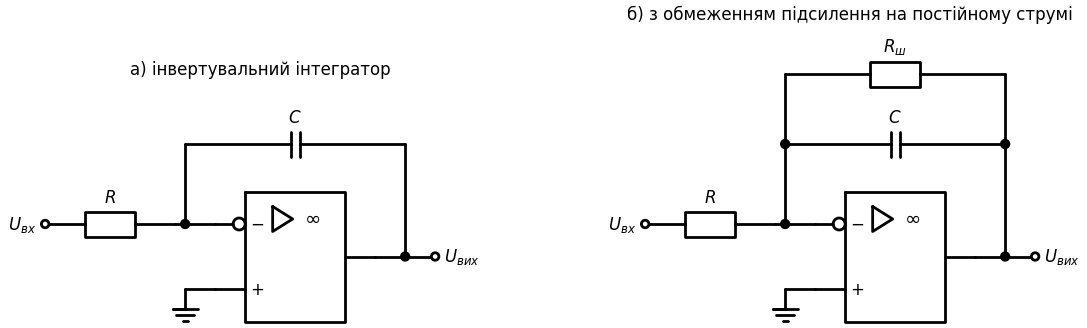

In [2]:
# а) інтегратор; б) інтегратор з обмеженням підсилення (R_ш)
if SCHEMDRAW_AVAILABLE:

    def inv_stage(d, ox, inp, fb, fb2=None, title='', inp2=None):
        """Інвертувальна схема на ОП. inp, inp2, fb, fb2 — пари (клас елемента, підпис):
        inp (і послідовний inp2) — вхідне коло, fb — коло ЗЗ, fb2 — паралельне йому."""
        mk = lambda e: e[0]().label(e[1])
        W = lambda p1, p2: elm.Line().at((ox + p1[0], p1[1])).to((ox + p2[0], p2[1]))
        if title:
            d += elm.Label().at((ox + 4.2, 6.3 if fb2 else 5.0)).label(title)
        if inp2 is None:
            d += elm.Dot(open=True).at((ox, 2)).label('$U_{вх}$', loc='left')
            d += mk(inp).at((ox, 2)).to((ox + 2.6, 2))
        else:
            d += elm.Dot(open=True).at((ox - 1.6, 2)).label('$U_{вх}$', loc='left')
            d += mk(inp).at((ox - 1.6, 2)).to((ox + 0.6, 2)); d += mk(inp2).at((ox + 0.6, 2)).to((ox + 2.6, 2))
        d += W((2.6, 2), (3.4, 2)); d += elm.Dot().at((ox + 2.8, 2))
        d += (o := OpAmp().at((ox + 3.4, 2)).anchor('in1'))
        d += W((2.8, 2), (2.8, 3.6)); d += mk(fb).at((ox + 2.8, 3.6)).to((ox + 7.2, 3.6))
        if fb2 is not None:
            d += elm.Dot().at((ox + 2.8, 3.6)); d += elm.Dot().at((ox + 7.2, 3.6))
            d += W((2.8, 3.6), (2.8, 5.0)); d += mk(fb2).at((ox + 2.8, 5.0)).to((ox + 7.2, 5.0)); d += W((7.2, 5.0), (7.2, 3.6))
        d += W((7.2, 3.6), (7.2, o.out[1])); d += elm.Dot().at((ox + 7.2, o.out[1]))
        d += elm.Line().at(o.out).to((ox + 7.8, o.out[1])); d += elm.Dot(open=True).at((ox + 7.8, o.out[1])).label('$U_{вих}$', loc='right')
        d += elm.Line().at(o.in2).to((ox + 2.8, o.in2[1])); d += elm.Ground().at((ox + 2.8, o.in2[1]))
        return o

    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        inv_stage(d, 0, (elm.Resistor, '$R$'), (elm.Capacitor, '$C$'), title='а) інвертувальний інтегратор')
        inv_stage(d, 12, (elm.Resistor, '$R$'), (elm.Capacitor, '$C$'), (elm.Resistor, '$R_ш$'), title='б) з обмеженням підсилення на постійному струмі')

---
### 🔬 Інтерактивно: інтегратор на μA741: форми сигналів і дрейф (PySpice) <a class="anchor" id="integrator-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

На вхід інтегратора ($C = 10$ нФ) подано меандр або синус. Змінюйте $R$ і частоту: розмах трикутника $\Delta U = U_mT/(2RC)$ зростає зі зменшенням $RC$ і частоти — аж до насичення. Вимкніть $R_ш$ (поставте 0) і додайте постійну складову входу: інтегратор без обмеження підсилення «відпливає» в насичення.

</div>

In [3]:
# Інтегратор на μA741: перехідний аналіз
def integrator(R_k=10.0, f_kHz=1.0, shape='меандр', Rsh_k=1000.0, Udc_mV=0.0):
    C = 10e-9
    c = opamp_circuit('integrator')
    T = 1 / (f_kHz * 1e3)
    if shape == 'меандр':
        c.PulseVoltageSource('in', 'src', c.gnd, initial_value=-1 + Udc_mV * 1e-3, pulsed_value=1 + Udc_mV * 1e-3,
                             pulse_width=T / 2, period=T, rise_time=T / 1000, fall_time=T / 1000)
    else:
        c.SinusoidalVoltageSource('in', 'src', c.gnd, offset=Udc_mV * 1e-3, dc_offset=Udc_mV * 1e-3, amplitude=1, frequency=f_kHz * 1e3)
    c.R(1, 'src', 'm', R_k * 1e3); c.C(1, 'm', 'out', C)
    if Rsh_k > 0:
        c.R('sh', 'm', 'out', Rsh_k * 1e3)
    c.R(3, 'p', c.gnd, R_k * 1e3)
    add_opamp(c, 1, 'p', 'm', 'out')
    settle = 5 * Rsh_k * 1e3 * C if Rsh_k > 0 else 0.0          # чекаємо встановлення (стала часу R_ш·C)
    settle = np.ceil(settle / T) * T
    t, v = tran(c, T / 200, settle + 8 * T, start=settle)
    t = t - settle
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(t * 1e3, v['src'], 'k--', lw=1, label='$u_{вх}$'); ax.plot(t * 1e3, v['out'], color='#F44336', label='$u_{вих}$')
    ax.set_ylim(-15, 15); ax.set_xlabel('t, мс'); ax.set_ylabel('В'); ax.legend(loc='upper right')
    ax.set_title(f'RC = {R_k*C*1e3*1e3:.3g} мс,  f = {f_kHz:g} кГц' + ('' if Rsh_k > 0 else '  (без $R_ш$)'))
    plt.tight_layout(); plt.show()
    if shape == 'меандр':
        print(f'Теоретичний розмах трикутника ΔU = U_m·T/(2RC) = {1*T/(2*R_k*1e3*C):.2f} В')
    else:
        print(f'Теоретична амплітуда виходу U_m/(ωRC) = {1/(2*np.pi*f_kHz*1e3*R_k*1e3*C):.2f} В')

interact(integrator,
         R_k=widgets.FloatSlider(min=1, max=100, step=1, value=10, description='R (кОм)'),
         f_kHz=widgets.FloatLogSlider(base=10, min=-0.5, max=1.5, step=0.1, value=1, description='f (кГц)'),
         shape=widgets.ToggleButtons(options=['меандр', 'синус'], description='Вхід'),
         Rsh_k=widgets.FloatSlider(min=0, max=2000, step=50, value=1000, description='Rш (кОм)'),
         Udc_mV=widgets.FloatSlider(min=-100, max=100, step=5, value=0, description='U₀ (мВ)'));

interactive(children=(FloatSlider(value=10.0, description='R (кОм)', min=1.0, step=1.0), FloatLogSlider(value=…

---

## Диференціатори на ОП <a class="anchor" id="differentiator"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 2.11</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Виводити передавальну функцію диференціатора
> - Пояснювати, чому ідеальний диференціатор нестійкий і шумить, і як його коригують
> - Розраховувати практичний диференціатор

</div>

### Ідеальний диференціатор

Конденсатор $C$ — на вході, резистор $R$ — у колі ЗЗ. Струм конденсатора $i = C\,du_{вх}/dt$ тече через $R$:
$$u_{вих}(t) = -RC\frac{du_{вх}}{dt},\qquad K(j\omega) = -j\omega RC .$$
АЧХ зростає з нахилом **+20 дБ/дек**; трикутна напруга перетворюється на прямокутну, синус — на косинус, лінійно змінна напруга — на постійну.

### Проблеми ідеального диференціатора

1. **Шум і завади**: підсилення зростає з частотою, тому високочастотні шуми і завади підсилюються найбільше.
2. **Нестійкість**: ланка ЗЗ $\beta(j\omega) = \dfrac{1}{1 + j\omega RC}$ — це ФНЧ з фазовим зсувом до $-90°$; разом із $-90°$ домінантного полюса ОП фаза петлі сягає $-180°$. Логарифмічний критерій: АЧХ кола $1/\beta$ (зростає +20 дБ/дек) перетинає АЧХ ОП (спадає −20 дБ/дек) з різницею нахилів 40 дБ/дек — запас стійкості близький до нуля. Схема дзвенить або генерує на частоті $\approx\sqrt{f_1/(2\pi RC)}$.
3. **Малий вхідний опір** на високих частотах ($1/\omega C \to 0$) — джерело сигналу перевантажується.

### Практичний (скоригований) диференціатор

Послідовно з $C$ вмикають резистор $R_1$, а паралельно $R$ — конденсатор $C_1$:
$$K(j\omega) = -\frac{j\omega RC}{(1 + j\omega R_1C)(1 + j\omega RC_1)} .$$
Схема диференціює лише до частоти $f_д \approx 1/(2\pi R_1C)$, вище — працює як інвертувальний підсилювач з $K = -R/R_1$, а потім підсилення спадає. Вибір $R_1C \approx RC_1$ і $f_д \ll f_1$ забезпечує запас стійкості й обмежує шум. $R_1$ також обмежує вхідний струм від крутих фронтів.

**Застосування:** виділення фронтів (детектори зміни рівня, формувачі коротких імпульсів), Д-складова ПІД-регуляторів, вимірювання швидкості зміни сигналів (давачі прискорення за сигналом швидкості), коректори частотних характеристик (підйом ВЧ), аналогові обчислення. Через проблеми з шумом диференціатори застосовують значно рідше, ніж інтегратори; часто замість них використовують інтегратор у петлі ЗЗ.

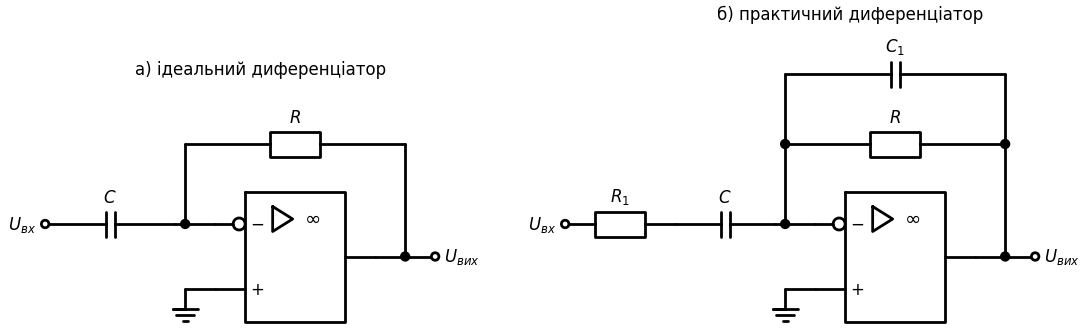

In [4]:
# а) ідеальний диференціатор; б) практичний диференціатор з R_1 і C_1
if SCHEMDRAW_AVAILABLE:

    def inv_stage(d, ox, inp, fb, fb2=None, title='', inp2=None):
        """Інвертувальна схема на ОП. inp, inp2, fb, fb2 — пари (клас елемента, підпис):
        inp (і послідовний inp2) — вхідне коло, fb — коло ЗЗ, fb2 — паралельне йому."""
        mk = lambda e: e[0]().label(e[1])
        W = lambda p1, p2: elm.Line().at((ox + p1[0], p1[1])).to((ox + p2[0], p2[1]))
        if title:
            d += elm.Label().at((ox + 4.2, 6.3 if fb2 else 5.0)).label(title)
        if inp2 is None:
            d += elm.Dot(open=True).at((ox, 2)).label('$U_{вх}$', loc='left')
            d += mk(inp).at((ox, 2)).to((ox + 2.6, 2))
        else:
            d += elm.Dot(open=True).at((ox - 1.6, 2)).label('$U_{вх}$', loc='left')
            d += mk(inp).at((ox - 1.6, 2)).to((ox + 0.6, 2)); d += mk(inp2).at((ox + 0.6, 2)).to((ox + 2.6, 2))
        d += W((2.6, 2), (3.4, 2)); d += elm.Dot().at((ox + 2.8, 2))
        d += (o := OpAmp().at((ox + 3.4, 2)).anchor('in1'))
        d += W((2.8, 2), (2.8, 3.6)); d += mk(fb).at((ox + 2.8, 3.6)).to((ox + 7.2, 3.6))
        if fb2 is not None:
            d += elm.Dot().at((ox + 2.8, 3.6)); d += elm.Dot().at((ox + 7.2, 3.6))
            d += W((2.8, 3.6), (2.8, 5.0)); d += mk(fb2).at((ox + 2.8, 5.0)).to((ox + 7.2, 5.0)); d += W((7.2, 5.0), (7.2, 3.6))
        d += W((7.2, 3.6), (7.2, o.out[1])); d += elm.Dot().at((ox + 7.2, o.out[1]))
        d += elm.Line().at(o.out).to((ox + 7.8, o.out[1])); d += elm.Dot(open=True).at((ox + 7.8, o.out[1])).label('$U_{вих}$', loc='right')
        d += elm.Line().at(o.in2).to((ox + 2.8, o.in2[1])); d += elm.Ground().at((ox + 2.8, o.in2[1]))
        return o

    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        inv_stage(d, 0, (elm.Capacitor, '$C$'), (elm.Resistor, '$R$'), title='а) ідеальний диференціатор')
        inv_stage(d, 12, (elm.Resistor, '$R_1$'), (elm.Resistor, '$R$'), (elm.Capacitor, '$C_1$'),
                  title='б) практичний диференціатор', inp2=(elm.Capacitor, '$C$'))

---
### 🔬 Інтерактивно: диференціатор: ідеальний і скоригований (PySpice) <a class="anchor" id="diff-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Диференціатор на μA741 ($R = 10$ кОм, $C = 10$ нФ, $RC = 0{,}1$ мс) отримує трикутну напругу. Без корекції ($R_1 = 0$, $C_1 = 0$) після кожного зламу трикутника виникає тривалий «дзвін» — запас стійкості майже нульовий. Додайте $R_1$ (і $C_1$): вихід стає чистим меандром з амплітудою $RC\cdot du/dt$. Праворуч — АЧХ обох варіантів.

</div>

In [5]:
# Диференціатор на μA741: перехідний і частотний аналіз
def differentiator(R1=0.0, C1_pF=0.0, f_kHz=0.5):
    R, C = 10e3, 10e-9
    def build(r1, c1, tri=True):
        c = opamp_circuit('differentiator')
        T = 1 / (f_kHz * 1e3)
        if tri:
            c.PulseVoltageSource('in', 'src', c.gnd, initial_value=-1, pulsed_value=1, pulse_width=1e-9, period=T, rise_time=T / 2, fall_time=T / 2 - 1e-9)
        else:
            c.SinusoidalVoltageSource('in', 'src', c.gnd, amplitude=1e-3, ac_magnitude=1)
        if r1 > 0:
            c.R(1, 'src', 'x', r1); c.C(1, 'x', 'm', C)
        else:
            c.C(1, 'src', 'm', C)
        c.R('f', 'm', 'out', R)
        if c1 > 0:
            c.C('f', 'm', 'out', c1 * 1e-12)
        add_opamp(c, 1, c.gnd, 'm', 'out')
        return c
    T = 1 / (f_kHz * 1e3)
    t, v = tran(build(R1, C1_pF), T / 1000, 3 * T, start=T)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
    a1.plot((t - t[0]) * 1e3, v['src'], 'k--', lw=1, label='$u_{вх}$ (трикутник ±1 В)')
    a1.plot((t - t[0]) * 1e3, v['out'], color='#F44336', label='$u_{вих}$')
    a1.axhline(R * C * 4 * f_kHz * 1e3, color='#4CAF50', ls=':', label='$\\pm RC\\,du/dt$'); a1.axhline(-R * C * 4 * f_kHz * 1e3, color='#4CAF50', ls=':')
    a1.set_xlabel('t, мс'); a1.set_ylabel('В'); a1.legend(fontsize=9, loc='upper right'); a1.set_title(f'$R_1$ = {R1:.0f} Ом, $C_1$ = {C1_pF:.0f} пФ')
    for (r1, c1), col, lab in (((0, 0), '#9E9E9E', 'ідеальний'), ((R1, C1_pF), '#F44336', 'з корекцією')):
        f, vv = ac(build(r1, c1, False), 10, 1e7, 40)
        a2.semilogx(f, db(vv['out']), color=col, label=lab)
    f = np.logspace(1, 7, 200)
    a2.semilogx(f, db(2 * np.pi * f * R * C), 'k:', lw=1, label='$\\omega RC$')
    a2.set_ylim(-20, 60); a2.set_xlabel('Частота, Гц'); a2.set_ylabel('K, дБ'); a2.legend(fontsize=9); a2.set_title('АЧХ')
    plt.tight_layout(); plt.show()
    print(f'Власна частота «дзвону» ≈ √(f₁/(2πRC)) = {np.sqrt(1e6/(2*np.pi*R*C))/1e3:.1f} кГц;  '
          + (f'межа диференціювання 1/(2πR₁C) = {1/(2*np.pi*R1*C)/1e3:.1f} кГц' if R1 > 0 else 'R₁ = 0'))

interact(differentiator,
         R1=widgets.FloatSlider(min=0, max=2000, step=50, value=0, description='R1 (Ом)'),
         C1_pF=widgets.FloatSlider(min=0, max=2000, step=50, value=0, description='C1 (пФ)'),
         f_kHz=widgets.FloatSlider(min=0.1, max=2, step=0.1, value=0.5, description='f (кГц)'));

interactive(children=(FloatSlider(value=0.0, description='R1 (Ом)', max=2000.0, step=50.0), FloatSlider(value=…

---

## Вимірювальні підсилювачі <a class="anchor" id="inamp"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 2.12</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати вимоги до вимірювальних підсилювачів і недоліки простого диференціального підсилювача
> - Аналізувати схему вимірювального підсилювача на трьох ОП і розраховувати його коефіцієнт підсилення
> - Знати області застосування вимірювальних підсилювачів

</div>

**Вимірювальний (інструментальний) підсилювач** — прецизійний диференціальний підсилювач з дуже великим і **однаковим** вхідним опором обох входів, великим КПСС (100…130 дБ), точно заданим (зазвичай одним резистором) коефіцієнтом підсилення і малим дрейфом. Він підсилює малу різницю напруг на тлі великої синфазної напруги — типова ситуація для мостових датчиків, термопар, біопотенціалів, сигналів у промислових лініях.

Простий диференціальний підсилювач на одному ОП (тема 7) для цього непридатний: його вхідні опори малі й неоднакові (джерело з внутрішнім опором розбалансовує міст резисторів і погіршує КПСС), а зміна підсилення вимагає одночасної зміни двох пар резисторів.

### Вимірювальний підсилювач на трьох ОП

**Вхідний каскад** — два неінвертувальні підсилювачі (DA1, DA2) зі спільним резистором $R_G$. Через віртуальне КЗ на кінцях $R_G$ діють напруги $U_1$ і $U_2$, струм $(U_1 - U_2)/R_G$ протікає через обидва резистори $R$, тому
$$U_{A} - U_{B} = (U_1 - U_2)\left(1 + \frac{2R}{R_G}\right),$$
а синфазна складова проходить з коефіцієнтом **1** (не підсилюється!). Вхідні опори — гігаоми, однакові.

**Вихідний каскад** DA3 — диференціальний підсилювач з коефіцієнтом $R_2/R_1$ — віднімає синфазну складову:
$$\boxed{U_{вих} = (U_2 - U_1)\left(1 + \frac{2R}{R_G}\right)\frac{R_2}{R_1}}$$
Підсилення регулюється **одним** резистором $R_G$ без впливу на КПСС. Загальний КПСС = (підсилення вхідного каскаду) × КПСС вихідного каскаду — тим більший, чим більше підсилення першого каскаду.

**Інтегральні вимірювальні підсилювачі** (INA128, AD620, INA333, AD8221) містять лазерно підігнані резистори; коефіцієнт задається $R_G$: для AD620 $K = 1 + 49{,}4\,\text{кОм}/R_G$. Інший різновид — **на двох ОП** (менше компонентів, але гірший КПСС на високих частотах).

**Застосування:** тензометричні мости (ваги, датчики тиску і сили), термопари і термометри опору, медична техніка (ЕКГ, ЕЕГ, ЕМГ — підсилення мікровольтових сигналів на тлі синфазної завади мережі 50 Гц у десятки–сотні мілівольт), шунтові вимірювачі струму, приймачі сигналів датчиків по довгих лініях (4–20 мА, мостові виходи), сейсмографи.

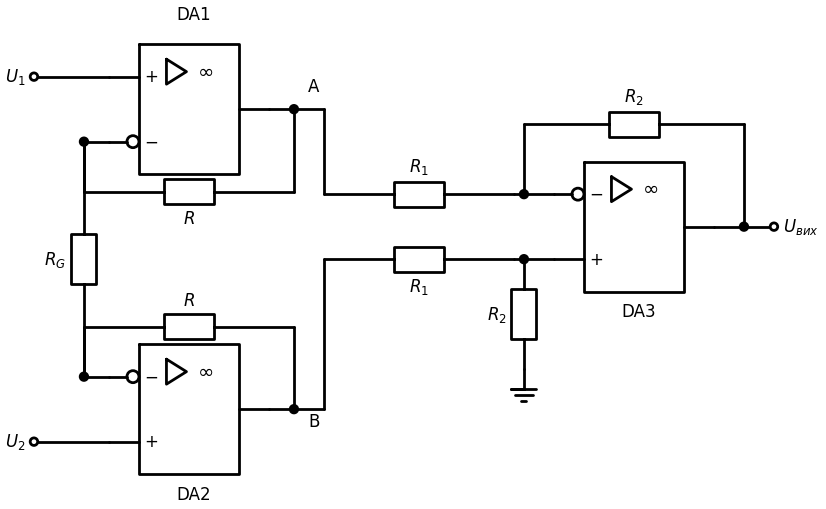

In [6]:
# Вимірювальний підсилювач на трьох ОП
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += (a1 := OpAmp(swap=True).at((1.5, 6.0)).anchor('in2'))       # DA1: «+» угорі, «−» внизу
        d += (a2 := OpAmp().at((1.5, 0.0)).anchor('in1'))                 # DA2: «−» угорі, «+» внизу
        d += elm.Label().at((a1.center[0], a1.center[1] + 1.8)).label('DA1'); d += elm.Label().at((a2.center[0], a2.center[1] - 1.8)).label('DA2')
        d += elm.Dot(open=True).at((0, a1.in2[1])).label('$U_1$', loc='left'); d += W((0, a1.in2[1]), a1.in2)
        d += elm.Dot(open=True).at((0, a2.in2[1])).label('$U_2$', loc='left'); d += W((0, a2.in2[1]), a2.in2)
        # мережа R – R_G – R між виходами DA1/DA2 та інвертувальними входами
        x = 1.0
        d += W(a1.in1, (x, a1.in1[1])); d += W(a2.in1, (x, a2.in1[1]))
        d += elm.Resistor().at((x, a1.in1[1])).to((x, a2.in1[1])).label('$R_G$', loc='top')
        d += elm.Dot().at((x, a1.in1[1])); d += elm.Dot().at((x, a2.in1[1]))
        xr = 5.2
        d += W((x, a1.in1[1]), (x, a1.in1[1] - 1.0)); d += elm.Resistor().at((x, a1.in1[1] - 1.0)).to((xr, a1.in1[1] - 1.0)).label('$R$', loc='bottom')
        d += W((xr, a1.in1[1] - 1.0), (xr, a1.out[1])); d += W(a1.out, (xr, a1.out[1])); d += elm.Dot().at((xr, a1.out[1]))
        d += W((x, a2.in1[1]), (x, a2.in1[1] + 1.0)); d += elm.Resistor().at((x, a2.in1[1] + 1.0)).to((xr, a2.in1[1] + 1.0)).label('$R$')
        d += W((xr, a2.in1[1] + 1.0), (xr, a2.out[1])); d += W(a2.out, (xr, a2.out[1])); d += elm.Dot().at((xr, a2.out[1]))
        d += elm.Label().at((xr + 0.3, a1.out[1] + 0.35)).label('A'); d += elm.Label().at((xr + 0.3, a2.out[1] - 0.35)).label('B')
        # вихідний диференціальний каскад DA3
        d += (a3 := OpAmp().at((10.4, 3.65)).anchor('in1'))
        d += elm.Label().at((a3.center[0], a3.center[1] - 1.8)).label('DA3')
        d += W((xr, a1.out[1]), (xr + 0.6, a1.out[1])); d += W((xr + 0.6, a1.out[1]), (xr + 0.6, a3.in1[1]))
        d += elm.Resistor().at((xr + 0.6, a3.in1[1])).to((9.6, a3.in1[1])).label('$R_1$'); d += W((9.6, a3.in1[1]), a3.in1); d += elm.Dot().at((9.8, a3.in1[1]))
        d += W((xr, a2.out[1]), (xr + 0.6, a2.out[1])); d += W((xr + 0.6, a2.out[1]), (xr + 0.6, a3.in2[1]))
        d += elm.Resistor().at((xr + 0.6, a3.in2[1])).to((9.6, a3.in2[1])).label('$R_1$', loc='bottom'); d += W((9.6, a3.in2[1]), a3.in2); d += elm.Dot().at((9.8, a3.in2[1]))
        d += elm.Resistor().at((9.8, a3.in2[1])).to((9.8, a3.in2[1] - 2.2)).label('$R_2$', loc='top'); d += elm.Ground().at((9.8, a3.in2[1] - 2.2))
        d += W((9.8, a3.in1[1]), (9.8, a3.in1[1] + 1.4)); d += elm.Resistor().at((9.8, a3.in1[1] + 1.4)).to((14.2, a3.in1[1] + 1.4)).label('$R_2$')
        d += W((14.2, a3.in1[1] + 1.4), (14.2, a3.out[1])); d += elm.Dot().at((14.2, a3.out[1]))
        d += W(a3.out, (14.8, a3.out[1])); d += elm.Dot(open=True).at((14.8, a3.out[1])).label('$U_{вих}$', loc='right')

---
### 🔬 Інтерактивно: вимірювальний підсилювач проти простого диференціального: сигнал ЕКГ на тлі мережевої завади (PySpice) <a class="anchor" id="inamp-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Корисний диференціальний сигнал — імпульси 1 мВ (≈ форма QRS-комплексу ЕКГ), синфазна завада — 50 Гц амплітудою $U_{сф}$. Джерело має опори електродів $R_{ел}$ і розбаланс $\Delta R_{ел}$. Порівнюються: (1) простий диференціальний підсилювач з $K = 100$ і резисторами з допуском 1 %; (2) вимірювальний підсилювач на трьох ОП з $K = 1 + 2R/R_G = 100$ (вихідний каскад з $K = 1$ і тими самими 1 % резисторами). У простого підсилювача вхідні опори — 10 кОм, тому розбаланс електродів перетворює синфазну заваду на диференціальну.

</div>

In [7]:
# Простий диференціальний і вимірювальний (3 ОП) підсилювачі: придушення синфазної завади
def inamp(Ucm=1.0, Rel_k=10.0, dRel_k=5.0):
    def sources(c):
        c.SinusoidalVoltageSource('cm', 'cm', c.gnd, amplitude=Ucm, frequency=50)
        c.PulseVoltageSource('sig', 'p1', 'cm', initial_value=0, pulsed_value=1e-3, delay_time=5e-3,
                             rise_time=10e-3, fall_time=10e-3, pulse_width=1e-6, period=100e-3)        # «QRS» 1 мВ
        c.R('e1', 'p1', 'in2', Rel_k * 1e3 + dRel_k * 1e3); c.R('e2', 'cm', 'in1', Rel_k * 1e3)
    tol = 1.01                                   # резистор з допуском +1 %
    c = opamp_circuit('simple diff')
    sources(c)
    c.R(1, 'in1', 'm', 10e3); c.R(2, 'm', 'out', 1e6); c.R(3, 'in2', 'p', 10e3); c.R(4, 'p', c.gnd, 1e6 * tol)
    add_opamp(c, 1, 'p', 'm', 'out')
    t, v1 = tran(c, 50e-6, 0.1)
    c = opamp_circuit('3-opamp inamp')
    sources(c)
    R, RG = 49.5e3, 1e3
    add_opamp(c, 1, 'in2', 'n1', 'A'); add_opamp(c, 2, 'in1', 'n2', 'B')
    c.R('a', 'A', 'n1', R); c.R('g', 'n1', 'n2', RG); c.R('b', 'n2', 'B', R)
    c.R(1, 'B', 'm', 10e3); c.R(2, 'm', 'out', 10e3); c.R(3, 'A', 'p', 10e3); c.R(4, 'p', c.gnd, 10e3 * tol)
    add_opamp(c, 3, 'p', 'm', 'out')
    t2, v2 = tran(c, 50e-6, 0.1)
    fig, ax = plt.subplots(3, 1, figsize=(9, 7.5), sharex=True)
    ax[0].plot(t * 1e3, (v1['in2'] - v1['in1']) * 1e3, color='#9C27B0'); ax[0].set_ylabel('мВ'); ax[0].set_title(f'Вхід ОП: різниця напруг (синфазна завада {Ucm*1e3:.0f} мВ, 50 Гц) — у простого підсилювача')
    ax[1].plot(t * 1e3, v1['out'], color='#2196F3'); ax[1].set_ylabel('В'); ax[1].set_title('Простий диференціальний підсилювач, K = 100')
    ax[2].plot(t2 * 1e3, v2['out'], color='#F44336'); ax[2].set_ylabel('В'); ax[2].set_title('Вимірювальний підсилювач (3 ОП), K = 100')
    ax[2].set_xlabel('t, мс')
    for a in ax[1:]:
        a.axhline(0.1, color='k', ls=':', lw=1)
    plt.tight_layout(); plt.show()

interact(inamp,
         Ucm=widgets.FloatSlider(min=0, max=2, step=0.05, value=1.0, description='Uсф (В)'),
         Rel_k=widgets.FloatSlider(min=1, max=100, step=1, value=10, description='Rел (кОм)'),
         dRel_k=widgets.FloatSlider(min=0, max=20, step=0.5, value=5, description='ΔRел (кОм)'));

interactive(children=(FloatSlider(value=1.0, description='Uсф (В)', max=2.0, step=0.05), FloatSlider(value=10.…

---

## Перетворювачі напруги в струм (джерела струму) на ОП <a class="anchor" id="v2i"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 2.13</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Аналізувати перетворювачі напруги в струм з плаваючим і заземленим навантаженням
> - Розраховувати джерело струму Хауленда і умову його балансу
> - Пояснювати роль транзистора у джерелі струму на ОП

</div>

**Перетворювач напруга → струм (ПНС, крутизнний підсилювач)** формує в навантаженні струм, пропорційний вхідній напрузі і **незалежний від опору навантаження**: $I_н = S\,U_{вх}$. Це послідовний (або паралельний) НЗЗ **за струмом** (тема 2): ЗЗ знімається з датчика струму, тому вихідний опір дуже великий.

### а) Плаваюче навантаження в колі ЗЗ

Навантаження $R_н$ вмикають замість $R_2$ інвертувального (або неінвертувального) підсилювача. Через віртуальну землю струм $U_{вх}/R_1$ тече через $R_н$ незалежно від його опору:
$$I_н = \frac{U_{вх}}{R_1}.$$
Недолік — навантаження не з'єднане із загальним проводом («плаває»); струм обмежений вихідним струмом ОП.

### б) ОП + транзистор (заземлене живлення, керований стік струму)

ОП керує базою (затвором) транзистора так, щоб напруга на резисторі датчика $R_д$ у колі емітера (витоку) дорівнювала $U_{вх}$:
$$I_н = \frac{U_{вх}}{R_д}\;(\text{для МДН — точно; для БТ — з похибкою } 1/\beta).$$
Навантаження вмикають між джерелом живлення і колектором (стоком). Транзистор розвантажує ОП і дозволяє отримати великі струми (світлодіоди, лазерні діоди, електроліз, тестування акумуляторів). Межа роботи: $I_нR_н + U_{вх} + U_{кенас} < E_ж$.

### в) Джерело струму Хауленда (заземлене навантаження)

ОП охоплено одночасно негативним (через $R_1, R_2$) і позитивним (через $R_3, R_4$) ЗЗ. При виконанні **умови балансу**
$$\frac{R_2}{R_1} = \frac{R_4}{R_3}\qquad\Rightarrow\qquad I_н = -\frac{U_{вх}}{R_3}\;(\text{для схеми з входом через } R_1\text{; при } R_1 = R_3,\;R_2 = R_4),$$
струм не залежить від $R_н$, а навантаження одним виводом заземлене. Розбаланс резисторів зменшує вихідний опір: $R_{вих} \approx R\cdot\dfrac{1}{\delta}$, де $\delta$ — відносна похибка відношень резисторів. Удосконалена схема — **«покращене джерело Хауленда»** з розділенням $R_4$ — має кращий ККД і не вимагає великих номіналів.

**Застосування:** живлення датчиків (термометри опору, тензомости струмом 1 мА), передавачі промислового інтерфейсу струмової петлі 4–20 мА, драйвери світлодіодів і лазерних діодів, керування котушками (відхиляючі системи, гальванометри), біоімпедансні вимірювання, генератори лінійно змінної напруги (заряд конденсатора стабільним струмом).

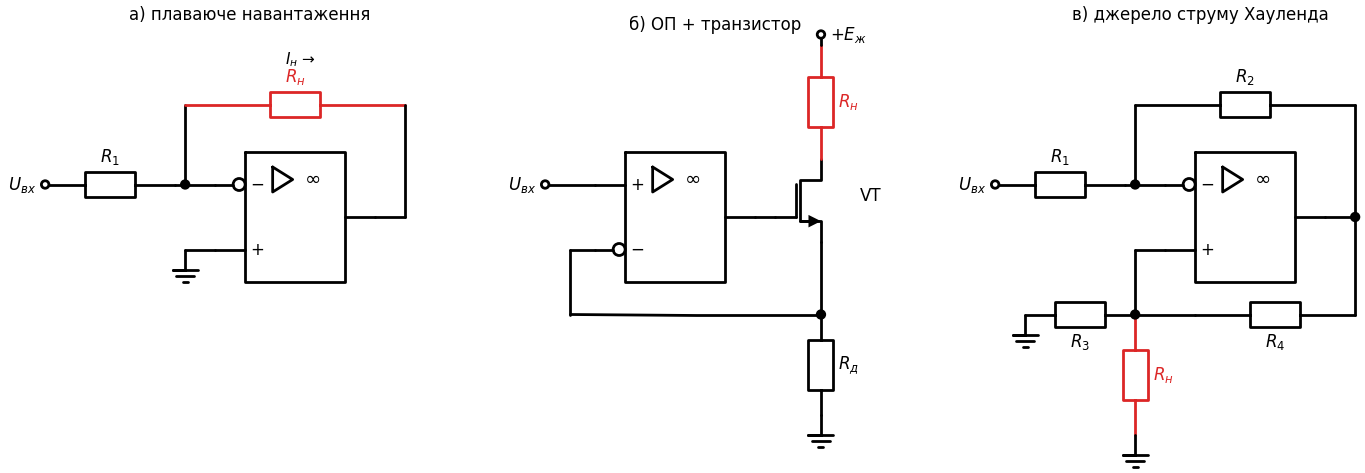

In [8]:
# а) плаваюче навантаження; б) ОП + транзистор; в) джерело струму Хауленда
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        # а)
        d += elm.Label().at((4.0, 5.3)).label('а) плаваюче навантаження')
        d += elm.Dot(open=True).at((0, 2)).label('$U_{вх}$', loc='left')
        d += elm.Resistor().at((0, 2)).to((2.6, 2)).label('$R_1$'); d += W((2.6, 2), (3.4, 2)); d += elm.Dot().at((2.8, 2))
        d += (o := OpAmp().at((3.4, 2)).anchor('in1'))
        d += W((2.8, 2), (2.8, 3.6)); d += elm.Resistor().at((2.8, 3.6)).to((7.2, 3.6)).label('$R_н$').color('#dc2626')
        d += elm.Label().at((5.0, 4.4)).label('$I_н$ →', fontsize=11)
        d += W((7.2, 3.6), (7.2, o.out[1])); d += W(o.out, (7.2, o.out[1]))
        d += W(o.in2, (2.8, o.in2[1])); d += elm.Ground().at((2.8, o.in2[1]))
        # б)
        ox = 10
        d += elm.Label().at((ox + 3.5, 5.3)).label('б) ОП + транзистор')
        d += (o := OpAmp(swap=True).at((ox + 1.0, 2)).anchor('in2'))        # «+» угорі, «−» унизу
        d += elm.Dot(open=True).at((ox, 2)).label('$U_{вх}$', loc='left'); d += W((ox, 2), (ox + 1.0, 2))
        d += W(o.out, (ox + 4.6, o.out[1]))
        d += (q := elm.AnalogNFet().theta(0).reverse().at((ox + 4.6, o.out[1])).anchor('gate'))
        d += elm.Label().at((q.center[0] + 0.9, q.center[1])).label('VT')
        d += elm.Resistor().at(q.drain).to((q.drain[0], 4.8)).label('$R_н$', loc='bottom').color('#dc2626'); d += W((q.drain[0], 4.8), (q.drain[0], 5.0))
        d += elm.Dot(open=True).at((q.drain[0], 5.0)).label('$+E_ж$', loc='right')
        d += W(q.source, (q.source[0], -0.6)); d += elm.Dot().at((q.source[0], -0.6))
        d += elm.Resistor().at((q.source[0], -0.6)).to((q.source[0], -2.6)).label('$R_д$', loc='bottom'); d += elm.Ground().at((q.source[0], -2.6))
        d += W((q.source[0], -0.6), (ox + 0.5, -0.6)); d += W((ox + 0.5, -0.6), (ox + 0.5, o.in1[1])); d += W((ox + 0.5, o.in1[1]), o.in1)
        # в) Хауленд
        ox = 19
        d += elm.Label().at((ox + 4.0, 5.3)).label('в) джерело струму Хауленда')
        d += elm.Dot(open=True).at((ox, 2)).label('$U_{вх}$', loc='left')
        d += elm.Resistor().at((ox, 2)).to((ox + 2.6, 2)).label('$R_1$'); d += W((ox + 2.6, 2), (ox + 3.4, 2)); d += elm.Dot().at((ox + 2.8, 2))
        d += (o := OpAmp().at((ox + 3.4, 2)).anchor('in1'))
        d += W((ox + 2.8, 2), (ox + 2.8, 3.6)); d += elm.Resistor().at((ox + 2.8, 3.6)).to((ox + 7.2, 3.6)).label('$R_2$')
        d += W((ox + 7.2, 3.6), (ox + 7.2, o.out[1])); d += W(o.out, (ox + 7.2, o.out[1])); d += elm.Dot().at((ox + 7.2, o.out[1]))
        d += W((ox + 7.2, o.out[1]), (ox + 7.2, -0.6)); d += elm.Resistor().at((ox + 7.2, -0.6)).to((ox + 4.0, -0.6)).label('$R_4$', loc='bottom')
        d += W(o.in2, (ox + 2.8, o.in2[1])); d += W((ox + 2.8, o.in2[1]), (ox + 2.8, -0.6)); d += W((ox + 2.8, -0.6), (ox + 4.0, -0.6)); d += elm.Dot().at((ox + 2.8, -0.6))
        d += elm.Resistor().at((ox + 2.8, -0.6)).to((ox + 0.6, -0.6)).label('$R_3$', loc='bottom'); d += elm.Ground().at((ox + 0.6, -0.6))
        d += elm.Resistor().at((ox + 2.8, -0.6)).to((ox + 2.8, -3.0)).label('$R_н$', loc='bottom').color('#dc2626'); d += elm.Ground().at((ox + 2.8, -3.0))

---
### 🔬 Інтерактивно: незалежність струму від опору навантаження (PySpice) <a class="anchor" id="v2i-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Для трьох схем (μA741, $U_{вх} = 1$ В, задано струм 1 мА) змінюємо опір навантаження від 10 Ом до 20 кОм. Струм залишається сталим, доки ОП (або транзистор) не досягає межі вихідної напруги — далі джерело «насичується». Змінюйте допуск резисторів схеми Хауленда і спостерігайте зменшення вихідного опору (струм починає залежати від $R_н$).

</div>

In [9]:
# Перетворювачі напруга→струм: I_н(R_н) для трьох схем
def v2i(tol_pct=0.0):
    Rl = np.logspace(1, np.log10(2e4), 40)
    res = {}
    for kind in ('плаваюче', 'ОП + МДН', 'Хауленд'):
        I = []
        for r in Rl:
            c = opamp_circuit(kind)
            c.V('in', 'in', c.gnd, 1.0)
            if kind == 'плаваюче':
                c.R(1, 'in', 'm', 1e3); c.R('L', 'm', 'out', r); add_opamp(c, 1, c.gnd, 'm', 'out'); probe = ('m', 'out')
            elif kind == 'ОП + МДН':
                c.model('NM', 'NMOS', LEVEL=1, VTO=2.0, KP=0.05)
                add_opamp(c, 1, 'in', 's', 'g'); c.MOSFET(1, 'd', 'g', 's', 's', model='NM')
                c.R('s', 's', c.gnd, 1e3); c.R('L', 'vcc', 'd', r); probe = ('vcc', 'd')
            else:
                k = 1 + tol_pct / 100
                c.R(1, 'in', 'm', 1e3); c.R(2, 'm', 'out', 1e3); c.R(3, 'p', c.gnd, 1e3); c.R(4, 'out', 'p', 1e3 * k)
                add_opamp(c, 1, 'p', 'm', 'out'); c.R('L', 'p', c.gnd, r)
                op = c.simulator(temperature=25, nominal_temperature=25).operating_point()
                vp = float(np.array(op['p'])[0]); I.append(abs(vp / r)); continue
            op = c.simulator(temperature=25, nominal_temperature=25).operating_point()
            I.append(abs((float(np.array(op[probe[0]])[0]) - float(np.array(op[probe[1]])[0])) / r))
        res[kind] = np.array(I)
    fig, ax = plt.subplots(figsize=(9, 4))
    for (kind, I), col in zip(res.items(), ('#2196F3', '#4CAF50', '#F44336')):
        ax.semilogx(Rl, I * 1e3, color=col, marker='o', ms=3, label=kind)
    ax.axhline(1.0, color='k', ls=':', lw=1)
    ax.set_xlabel('$R_н$, Ом'); ax.set_ylabel('$I_н$, мА'); ax.set_ylim(0, 1.3); ax.legend()
    ax.set_title(f'Перетворювачі напруга → струм ($U_{{вх}}$ = 1 В, допуск резисторів Хауленда {tol_pct:g} %)')
    plt.tight_layout(); plt.show()
    print('Струм сталий, доки вихідна напруга ОП (≈ ±13 В) достатня: для плаваючого навантаження I·R_н < 13 В, для схеми Хауленда — ≈ I·2R_н < 13 В')

interact(v2i, tol_pct=widgets.FloatSlider(min=0, max=5, step=0.5, value=0, description='допуск (%)'));

interactive(children=(FloatSlider(value=0.0, description='допуск (%)', max=5.0, step=0.5), Output()), _dom_cla…

---

## Перетворювачі струму в напругу на ОП <a class="anchor" id="i2v"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 2.14</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати роботу трансімпедансного підсилювача (ПСН)
> - Розраховувати коефіцієнт перетворення і коригувальну ємність підсилювача фотодіода
> - Знати застосування перетворювачів струм → напруга

</div>

**Перетворювач струм → напруга (ПСН, трансімпедансний підсилювач, TIA)** — інвертувальний підсилювач без вхідного резистора: джерело струму під'єднується безпосередньо до віртуальної землі, і весь його струм тече через резистор ЗЗ $R_{зз}$:
$$U_{вих} = -I_{вх}R_{зз}.$$
Коефіцієнт перетворення (трансопір) $R_т = R_{зз}$ (В/А). Це паралельний НЗЗ за напругою — вхідний опір схеми
$$R_{вх} = \frac{R_{зз}}{1 + K_0}\to 0,$$
тобто ПСН — майже ідеальний **амперметр**: напруга на джерелі струму (фотодіоді, датчику) підтримується нульовою, що усуває вплив його ємності і струму витоку і забезпечує лінійність.

### Підсилювач фотодіода і його стійкість

Фотодіод у фотогальванічному (без зміщення) або фотодіодному (зі зворотним зміщенням) режимі дає струм, пропорційний освітленості. Його ємність $C_д$ (десятки–сотні пФ) разом з $R_{зз}$ утворює в колі ЗЗ ФНЧ: $\beta(j\omega) = \dfrac{1}{1 + j\omega R_{зз}C_д}$ — фаза петлі наближається до $-180°$, і, як у диференціатора, з'являються дзвін або генерація. Корекція — конденсатор $C_{зз}$ паралельно $R_{зз}$. Оптимальне значення (запас за фазою ≈ 45…65°):
$$C_{зз} \approx \sqrt{\frac{C_д}{2\pi R_{зз}f_1}},\qquad f_{-3дБ} \approx \sqrt{\frac{f_1}{2\pi R_{зз}C_д}}\;(\text{до корекції — власна частота дзвону}).$$
Смуга скоригованого ПСН $\approx 1/(2\pi R_{зз}C_{зз})$.

**Інші ПСН:** логарифмічний перетворювач (діод/транзистор у колі ЗЗ — тема 9), ПСН з Т-мостом у колі ЗЗ (великий трансопір малими резисторами), перетворювач для датчиків струму (шунт + вимірювальний підсилювач), підсилювач заряду (конденсатор у ЗЗ — для п'єзодатчиків).

**Застосування:** приймачі оптичного зв'язку і лідарів, фотометри, пульсоксиметри, датчики диму і полум'я, вимірювання малих струмів (електрометри, pH-метри, іонізаційні камери, фотопомножувачі), виходи струмових ЦАП, детектори в мас-спектрометрах.

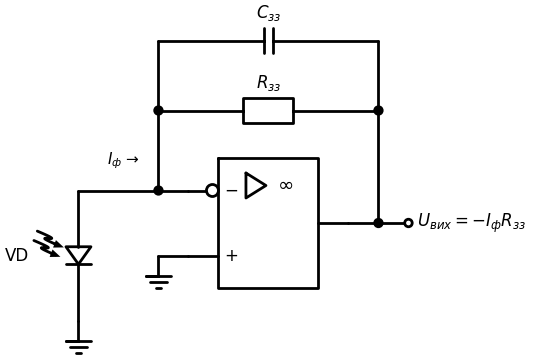

In [10]:
# Перетворювач струм → напруга для фотодіода (C_д — ємність фотодіода, C_зз — коригувальна)
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += (o := OpAmp().at((3.4, 2)).anchor('in1'))
        d += elm.Photodiode().theta(90).at((1.2, -0.6)).to((1.2, 2)).reverse().label('VD', loc='top')
        d += elm.Ground().at((1.2, -0.6))
        d += W((1.2, 2), (3.4, 2)); d += elm.Dot().at((2.8, 2)); d += elm.Label().at((2.0, 2.5)).label('$I_ф$ →', fontsize=11)
        d += W((2.8, 2), (2.8, 3.6)); d += elm.Resistor().at((2.8, 3.6)).to((7.2, 3.6)).label('$R_{зз}$')
        d += elm.Dot().at((2.8, 3.6)); d += elm.Dot().at((7.2, 3.6))
        d += W((2.8, 3.6), (2.8, 5.0)); d += elm.Capacitor().at((2.8, 5.0)).to((7.2, 5.0)).label('$C_{зз}$'); d += W((7.2, 5.0), (7.2, 3.6))
        d += W((7.2, 3.6), (7.2, o.out[1])); d += elm.Dot().at((7.2, o.out[1]))
        d += W(o.out, (7.8, o.out[1])); d += elm.Dot(open=True).at((7.8, o.out[1])).label('$U_{вих} = -I_фR_{зз}$', loc='right')
        d += W(o.in2, (2.8, o.in2[1])); d += elm.Ground().at((2.8, o.in2[1]))

---
### 🔬 Інтерактивно: підсилювач фотодіода: стійкість і корекція (PySpice) <a class="anchor" id="tia-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Фотодіод моделюємо джерелом струму (імпульс світла 10 мкА) з паралельною ємністю $C_д$. ПСН на μA741 з $R_{зз} = 100$ кОм. Без $C_{зз}$ реакція на фронт — тривалий дзвін; збільшуйте $C_{зз}$ до оптимуму (див. оцінку під графіком) — дзвін зникає. Завеликі $C_{зз}$ надмірно звужують смугу.

</div>

In [11]:
# ПСН (TIA) на μA741: реакція на імпульс фотоструму
def tia(Cd_pF=100.0, Cf_pF=0.0):
    Rf = 100e3
    c = opamp_circuit('TIA')
    # струм задаємо з префіксом (10uA): запис «1e-05A» ngspice прочитав би як 1e-05 атто(!)ампер
    c.PulseCurrentSource('ph', c.gnd, 'm', initial_value=0@u_uA, pulsed_value=10@u_uA, delay_time=50e-6, rise_time=0.1e-6,
                         fall_time=0.1e-6, pulse_width=300e-6, period=1e-3)
    c.C('d', 'm', c.gnd, Cd_pF * 1e-12)
    c.R('f', 'm', 'out', Rf)
    if Cf_pF > 0:
        c.C('f', 'm', 'out', Cf_pF * 1e-12)
    add_opamp(c, 1, c.gnd, 'm', 'out')
    t, v = tran(c, 0.1e-6, 600e-6)
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(t * 1e6, v['out'], color='#F44336', label='$u_{вих}$')
    ax.axhline(-10e-6 * Rf, color='k', ls=':', lw=1, label='$-I_фR_{зз}$ = −1 В')
    ax.set_xlabel('t, мкс'); ax.set_ylabel('В'); ax.legend(loc='lower right')
    ax.set_title(f'$C_д$ = {Cd_pF:.0f} пФ, $C_{{зз}}$ = {Cf_pF:.0f} пФ')
    plt.tight_layout(); plt.show()
    f1 = 1e6
    print(f'Власна частота дзвону √(f₁/(2πR_ззC_д)) = {np.sqrt(f1/(2*np.pi*Rf*Cd_pF*1e-12))/1e3:.1f} кГц;  '
          f'оптимальна C_зз ≈ √(C_д/(2πR_зз·f₁)) = {np.sqrt(Cd_pF*1e-12/(2*np.pi*Rf*f1))*1e12:.0f} пФ')

interact(tia,
         Cd_pF=widgets.FloatSlider(min=10, max=1000, step=10, value=100, description='Cд (пФ)'),
         Cf_pF=widgets.FloatSlider(min=0, max=200, step=1, value=0, description='Cзз (пФ)'));

interactive(children=(FloatSlider(value=100.0, description='Cд (пФ)', max=1000.0, min=10.0, step=10.0), FloatS…

### ⚠️ Типова помилка

<div style="background-color: #fef2f2; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #dc2626; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

**Ємність джерела на вході ОП — головний ворог стійкості.** Ємність фотодіода, кабелю чи входу ОП, що з'єднана з інвертувальним входом, разом з резистором ЗЗ створює полюс у ланці $\beta$. Через це «дзвенять» ідеальні диференціатори, підсилювачі фотодіодів і навіть звичайні інвертувальні підсилювачі з високоомними резисторами. Ліки однакові — невеликий конденсатор паралельно резистору ЗЗ.

</div>

---
### ⚡ Практичне застосування: лінійні перетворювачі на ОП

<div style="background-color: #fffbeb; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #f59e0b; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Пристрій | Схема | Співвідношення |
|---|---|---|
| АЦП подвійного інтегрування (мультиметр) | інтегратор з ключем скидання | $\Delta u = U_{вх}T/(RC)$ |
| ПІД-регулятор температури | суматор П + І + Д ланок | $u = K_pe + K_i\int e\,dt + K_d\,de/dt$ |
| Електрокардіограф | вимірювальний підсилювач + ФВЧ 0,05 Гц + ФНЧ 100 Гц | $K = 1 + 2R/R_G$ |
| Цифрові ваги | тензоміст + вимірювальний підсилювач (INA125) + АЦП | КПСС > 100 дБ |
| Передавач 4–20 мА | ПНС на ОП + транзистор | $I = U/R_д$ |
| Драйвер лазерного діода | ОП + МДН-транзистор + шунт | $I = U/R_д$ |
| Оптичний приймач | TIA з корекцією $C_{зз}$ | $U = -I_фR_{зз}$ |
| Підсилювач п'єзодатчика | підсилювач заряду | $U = -Q/C_{зз}$ |

</div>

---
### ✅ Питання для самоперевірки: інтегратори, диференціатори, вимірювальні підсилювачі, перетворювачі

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Чому інтегратор без резистора $R_ш$ «дрейфує»?</summary>

> **Відповідь:** На постійному струмі конденсатор — розрив, ОП без ЗЗ: напруга зміщення і вхідний струм постійно інтегруються ($du/dt = U_{зм}/RC + I_{вх}/C$), і вихід доходить до насичення.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Чому ідеальний диференціатор нестійкий?</summary>

> **Відповідь:** Ланка ЗЗ — RC-ФНЧ з фазою до $-90°$, плюс $-90°$ домінантного полюса ОП дають $-180°$ на частоті, де петльове підсилення ще більше 1.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Чому вимірювальний підсилювач на трьох ОП має великий КПСС?</summary>

> **Відповідь:** Вхідний каскад підсилює диференціальний сигнал у $1 + 2R/R_G$ разів, а синфазний — в 1 раз; далі диференціальний каскад віднімає синфазну складову.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Як змінити підсилення вимірювального підсилювача?</summary>

> **Відповідь:** Одним резистором $R_G$: $K = (1 + 2R/R_G)R_2/R_1$; КПСС при цьому не погіршується.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Чим вигідний перетворювач струм → напруга для фотодіода?</summary>

> **Відповідь:** Напруга на фотодіоді підтримується нульовою (віртуальна земля): немає впливу ємності і струму витоку, висока лінійність; $U = -I_фR_{зз}$.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 6.</b> Яка умова балансу джерела струму Хауленда?</summary>

> **Відповідь:** $R_2/R_1 = R_4/R_3$; тоді вихідний струм $U_{вх}/R_3$ не залежить від опору навантаження.

</details>

---
### 📝 Задачі для самостійного розв'язання: лінійні перетворювачі


<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 1.** Інтегратор: $R = 10$ кОм, $C = 0{,}1$ мкФ, на вході меандр ±2 В, 500 Гц. Знайдіть розмах вихідного трикутника.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $\Delta U = U_mT/(2RC) = 2\cdot2\cdot10^{-3}/(2\cdot10^{-3}) = 2$ В.

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 2.** Вимірювальний підсилювач на трьох ОП з $R = 25$ кОм, $R_1 = R_2$. Яким має бути $R_G$ для $K = 1000$? Який вихідний сигнал при $U_1 = 2{,}500$ В, $U_2 = 2{,}502$ В?

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $1 + 50\,\text{к}/R_G = 1000 \Rightarrow R_G = 50{,}05$ Ом; $U_{вих} = 1000\cdot2\,\text{мВ} = 2$ В (синфазні 2,5 В не впливають).

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 3.** ПСН для фотодіода: $I_ф = 0\ldots5$ мкА, вихід 0…−5 В, $C_д = 50$ пФ, ОП з $f_1 = 10$ МГц. Знайдіть $R_{зз}$, $C_{зз}$ і смугу.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $R_{зз} = 1$ МОм; $C_{зз} \approx \sqrt{50\cdot10^{-12}/(2\pi\cdot10^6\cdot10^7)} \approx 0{,}9$ пФ; смуга $\approx 1/(2\pi R_{зз}C_{зз}) \approx 180$ кГц.

</details>

---

### 📌 Підсумок теми <a class="anchor" id="topic-summary"></a>

<div style="background-color: #f0fdf4; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #16a34a; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Схема | Співвідношення |
|---|---|
| Інтегратор | $u_{вих} = -\frac{1}{RC}\int u_{вх}dt$, $K = -1/(j\omega RC)$; $R_ш$ обмежує дрейф |
| Диференціатор | $u_{вих} = -RC\,du_{вх}/dt$, $K = -j\omega RC$; корекція $R_1$, $C_1$ |
| Вимірювальний підсилювач (3 ОП) | $U_{вих} = (U_2 - U_1)(1 + 2R/R_G)R_2/R_1$ |
| ПНС з плаваючим навантаженням / ОП+транзистор | $I_н = U_{вх}/R_1$ / $I_н = U_{вх}/R_д$ |
| Джерело Хауленда | $R_2/R_1 = R_4/R_3$, $I_н = -U_{вх}/R_3$ |
| ПСН (TIA) | $U_{вих} = -IR_{зз}$, $C_{зз} \approx\sqrt{C_д/(2\pi R_{зз}f_1)}$ |

**Головні висновки.** Замінюючи резистори кола ЗЗ і входу реактивними елементами, отримуємо операції інтегрування і диференціювання; з датчиком струму в колі ЗЗ — джерела струму; без вхідного резистора — вимірювач струму. Вимірювальний підсилювач розв'язує задачу виділення малого диференціального сигналу на тлі великої синфазної завади. Для всіх цих схем головні практичні питання — дрейф (інтегратор), стійкість при ємнісному колі ЗЗ (диференціатор, TIA) і точність резисторів (вимірювальний підсилювач, джерело Хауленда).

</div>

---

## 📚 Рекомендована література та ресурси <a class="anchor" id="references"></a>

**Основна література**

1. Гусев В. Г., Гусев Ю. М. Електроніка і мікропроцесорна техніка. — К.: Вища школа (укр. пер.).
2. Опадчий Ю. Ф., Глудкин О. П., Гуров А. И. Аналоговая и цифровая электроника. — М.: Горячая линия – Телеком, 2000.
3. Титце У., Шенк К. Полупроводниковая схемотехника. — 12-е изд. — М.: ДМК Пресс, 2008.
4. Хоровиц П., Хилл У. Искусство схемотехники. — М.: Мир / Horowitz P., Hill W. The Art of Electronics. — 3rd ed. — Cambridge University Press, 2015.
5. Sedra A. S., Smith K. C. Microelectronic Circuits. — 8th ed. — Oxford University Press, 2020.

**Додаткова література**

6. Kitchin C., Counts L. A Designer's Guide to Instrumentation Amplifiers. — 3rd ed. — Analog Devices, 2006.
7. Graeme J. Photodiode Amplifiers: Op Amp Solutions. — McGraw-Hill, 1996.
8. Pease R. A. A Comprehensive Study of the Howland Current Pump. — National Semiconductor AN-1515, 2008.

**Програмні інструменти, що використовуються в конспекті**

- [PySpice](https://pyspice.fabrice-salvaire.fr/) + [ngspice](https://ngspice.sourceforge.io/) — схемотехнічне моделювання
- [SchemDraw](https://schemdraw.readthedocs.io/) — побудова електричних схем
- [SymPy](https://docs.sympy.org/) — символьні обчислення
- [NumPy](https://numpy.org/doc/) / [SciPy](https://docs.scipy.org/doc/scipy/) / [Matplotlib](https://matplotlib.org/) — чисельні розрахунки та графіки

---

<p style="text-align: center;">⬅️ [Тема 7. Операційні підсилювачі. Основні схеми включення](Тема_07_Операційні_підсилювачі_основні_схеми.ipynb) &nbsp;|&nbsp; [Тема 9. Нелінійні схеми на ОП: компаратори, тригери Шмітта, прецизійні випрямлячі](Тема_09_Нелінійні_схеми_на_ОП.ipynb) ➡️</p>

*Конспект підготовлено: Пахалюк Богдан Петрович, НУ "Чернігівська політехніка"*